# Diagnóstico de la Bayesian Optimization (equivalente a los gráficos de Optuna, para mlrMBO)

Optuna trae de fábrica `plot_optimization_history`, `plot_param_importances`, `plot_slice`, y `plot_contour`. `mlrMBO` no los tiene armados, pero el `BO_log.txt` que ya generás en cada corrida tiene toda la información necesaria para reconstruirlos.

Usa el `BO_log.txt` de la corrida HT4961 (Salsa Mágica); ajustar la ruta si el log está en otra carpeta.

### Seteo del ambiente — versión LOCAL

In [1]:
PARAM_carpeta_exp <- "C:/Users/Laura/Documents/DMEyF/exp/"
require("data.table")
require("ggplot2")
if(!require("randomForest")) install.packages("randomForest")
require("randomForest")

Caricamento del pacchetto richiesto: data.table

Caricamento del pacchetto richiesto: ggplot2

Caricamento del pacchetto richiesto: randomForest

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Caricamento pacchetto: 'randomForest'


Il seguente oggetto è mascherato da 'package:ggplot2':

    margin




## 1. Cargo el log de la BO

In [2]:
archivo_log <- paste0(PARAM_carpeta_exp, "HT4961/BO_log.txt")  # ajustar carpeta si hace falta

bo_log <- fread(archivo_log)
bo_log[, iteracion := dob]  # dob = "date of birth": el numero de iteracion REAL de mlrMBO, no el orden de las filas del archivo

cat("Cantidad de evaluaciones en el log:", nrow(bo_log), "\n")
print(colnames(bo_log))

Cantidad de evaluaciones en el log: 144 
 [1] "num_iterations"    "learning_rate"     "feature_fraction" 
 [4] "num_leaves"        "min_data_in_leaf"  "scale_pos_weight" 
 [7] "min_gain_to_split" "lambda_l1"         "lambda_l2"        
[10] "bagging_fraction"  "bagging_freq"      "y"                
[13] "dob"               "eol"               "error.message"    
[16] "exec.time"         "ei"                "error.model"      
[19] "train.time"        "prop.type"         "propose.time"     
[22] "se"                "mean"              "iter"             
[25] "iteracion"        


## 2. Historial de optimización — equivalente a `plot_optimization_history`

Muestra el valor de cada evaluación, y la mejor ganancia encontrada hasta ese momento (la línea que "sube en escalones").

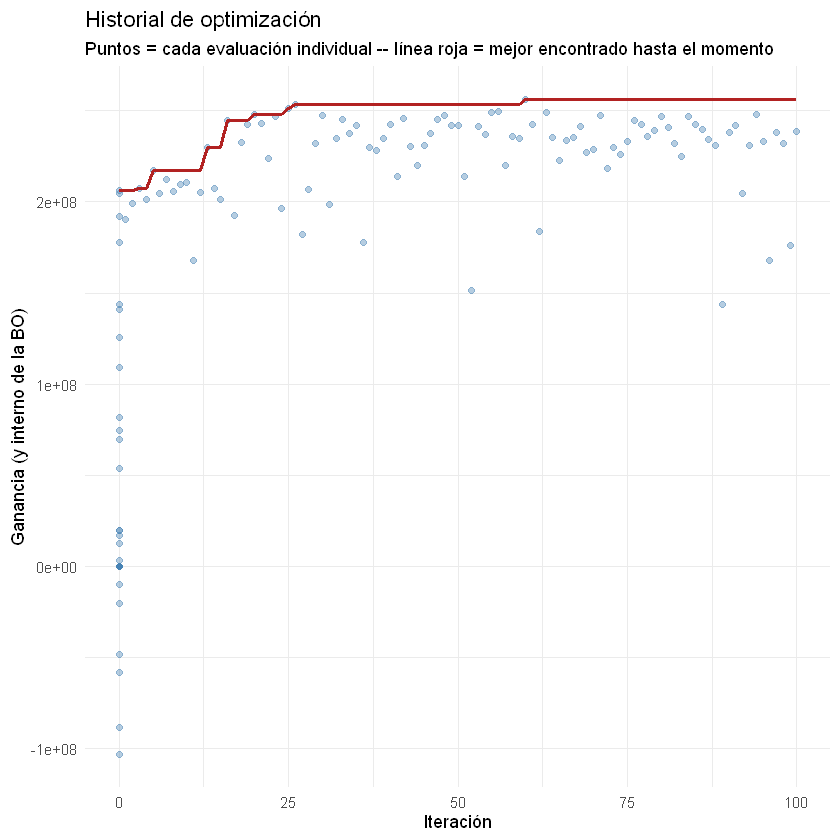

In [3]:
setorder(bo_log, iteracion)  # ordeno por iteracion real antes de calcular el acumulado
bo_log[, mejor_hasta_ahora := cummax(y)]

ggplot(bo_log, aes(x= iteracion)) +
  geom_point(aes(y= y), alpha= 0.4, color= "steelblue") +
  geom_line(aes(y= mejor_hasta_ahora), color= "firebrick", linewidth= 1) +
  labs(title= "Historial de optimización",
       subtitle= "Puntos = cada evaluación individual -- línea roja = mejor encontrado hasta el momento",
       x= "Iteración", y= "Ganancia (y interno de la BO)") +
  theme_minimal()

## 3. Importancia de los hiperparámetros — equivalente a `plot_param_importances`

Entreno un Random Forest chiquito sobre el propio log (hiperparámetros -> y) y miro qué tan importante fue cada uno para explicar el resultado -- NO es el modelo LightGBM en sí, es un modelo auxiliar sobre los DATOS DE LA BÚSQUEDA.

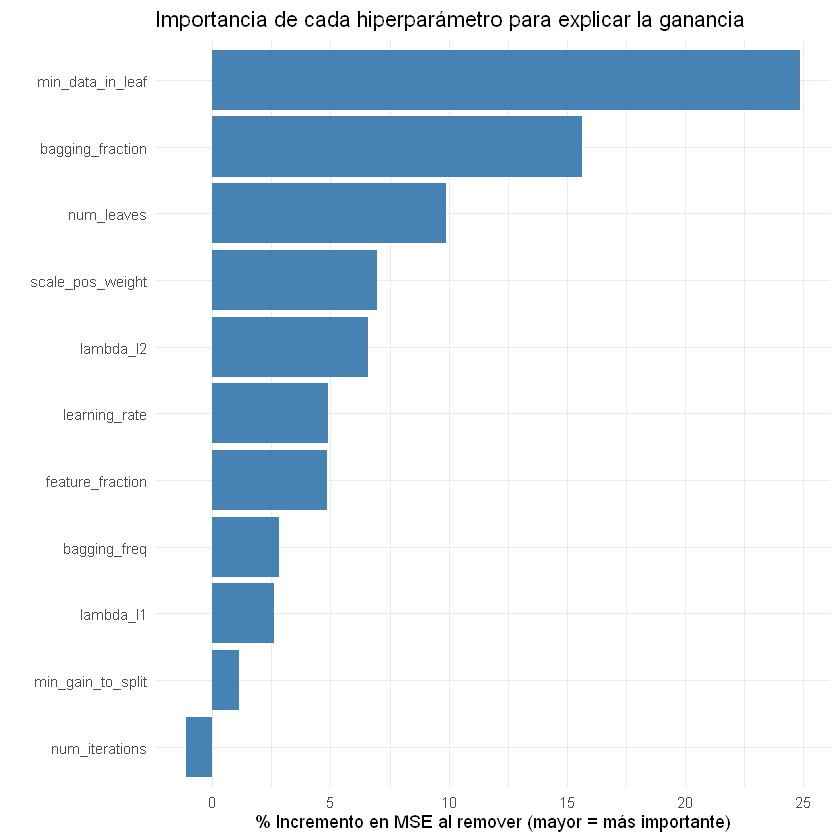

In [4]:
hp_cols <- c("num_iterations", "learning_rate", "feature_fraction", "num_leaves",
             "min_data_in_leaf", "scale_pos_weight", "min_gain_to_split",
             "lambda_l1", "lambda_l2", "bagging_fraction", "bagging_freq")
hp_cols <- intersect(hp_cols, colnames(bo_log))  # por si algun nombre no coincide exacto

set.seed(585581)
rf_importancia <- randomForest(
  x = bo_log[, ..hp_cols],
  y = bo_log$y,
  ntree = 300,
  importance = TRUE
)

imp <- importance(rf_importancia, type = 1)  # %IncMSE
tabla_imp <- data.table(hiperparametro = rownames(imp), importancia = imp[, 1])
setorder(tabla_imp, -importancia)

ggplot(tabla_imp, aes(x= reorder(hiperparametro, importancia), y= importancia)) +
  geom_col(fill= "steelblue") +
  coord_flip() +
  labs(title= "Importancia de cada hiperparámetro para explicar la ganancia",
       x= "", y= "% Incremento en MSE al remover (mayor = más importante)") +
  theme_minimal()

## 4. Slice plots — equivalente a `plot_slice`

Un scatter por cada hiperparámetro, mostrando su valor vs. la ganancia obtenida -- para ver si hay una zona visualmente mejor dentro del rango que probaste.

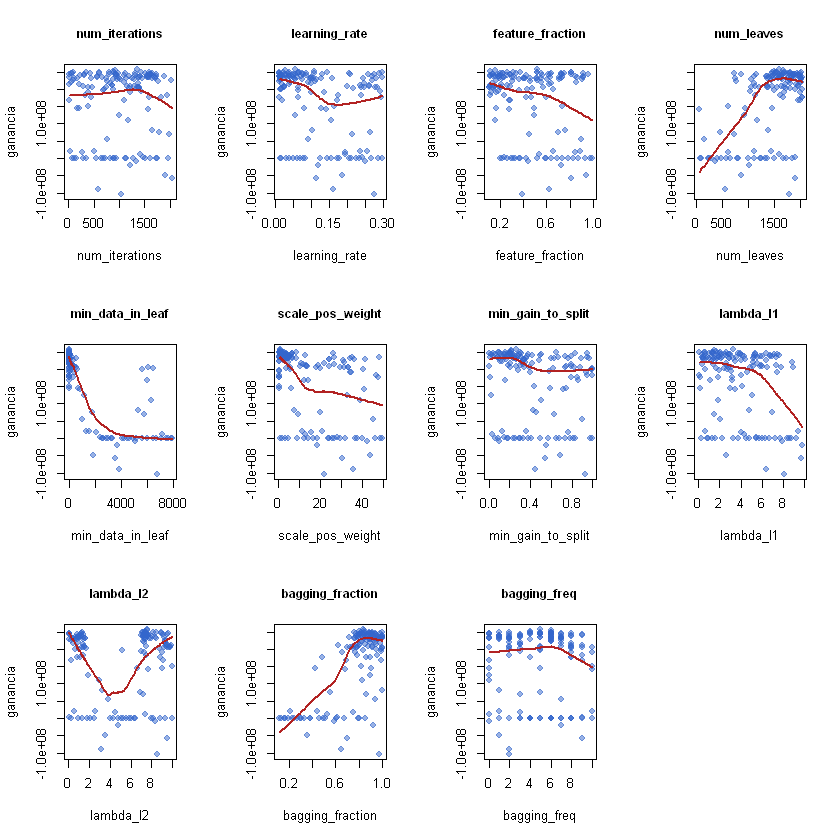

In [5]:
par(mfrow = c(3, 4))
for (hp in hp_cols) {
  plot(bo_log[[hp]], bo_log$y, pch= 19, col= rgb(0.2, 0.4, 0.8, 0.5),
       xlab= hp, ylab= "ganancia", main= hp, cex.main= 0.9)
  lowess_fit <- lowess(bo_log[[hp]], bo_log$y)
  lines(lowess_fit, col= "firebrick", lwd= 2)
}
par(mfrow = c(1, 1))

## 5. Contour plot — equivalente a `plot_contour`

Se eligen 2 hiperparámetros (por defecto `learning_rate` y `scale_pos_weight`, los mismos de las grillas posteriores) y se grafica un mapa de calor de la ganancia esperada en ese plano, interpolando entre los puntos que sí evaluó la BO.

Caricamento del pacchetto richiesto: akima

Warning message:
"The following aesthetics were dropped during statistical transformation: fill.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?"


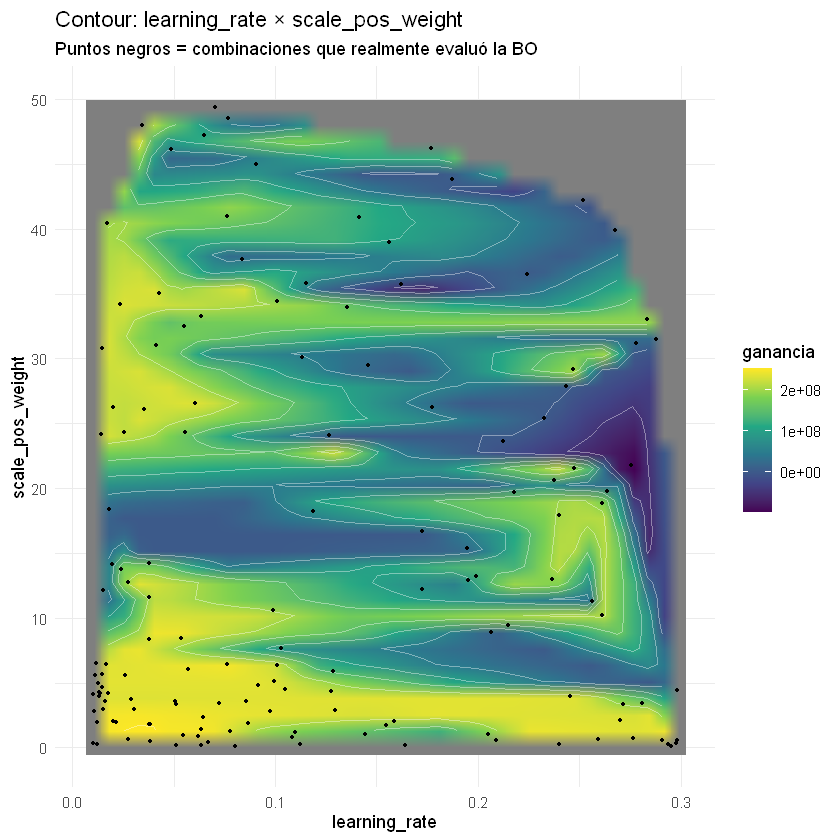

In [6]:
if(!require("akima")) install.packages("akima")
require("akima")

HP_X <- "learning_rate"
HP_Y <- "scale_pos_weight"

interpolado <- with(bo_log, interp(x= get(HP_X), y= get(HP_Y), z= y, duplicate= "mean"))

interpolado_df <- data.table(
  x = rep(interpolado$x, times = length(interpolado$y)),
  y = rep(interpolado$y, each = length(interpolado$x)),
  z = as.vector(interpolado$z)
)

ggplot(interpolado_df, aes(x= x, y= y, fill= z)) +
  geom_raster(interpolate= TRUE, na.rm= TRUE) +
  geom_contour(aes(z= z), color= "white", alpha= 0.4, na.rm= TRUE) +
  geom_point(data= bo_log, aes(x= get(HP_X), y= get(HP_Y), fill= NULL), color= "black", size= 0.8) +
  scale_fill_viridis_c(name= "ganancia") +
  labs(title= paste("Contour:", HP_X, "×", HP_Y),
       subtitle= "Puntos negros = combinaciones que realmente evaluó la BO",
       x= HP_X, y= HP_Y) +
  theme_minimal()